# 品质理论：转移矩阵、纯回收机与组装-回收环

官方文档：https://wiki.factorio.com/Quality/zh

## 1 基础转移矩阵

### 1.1 两个表达式

输出 = 输入 × 转移矩阵：

$$g = f\,M$$

转移矩阵 = 出入比例 × 品质矩阵（$Q$ 取 **Quality** 的首字母）：

$$M = \mathrm{diag}(r)\,Q(q)$$

### 1.1.1 记号与约定

- **品质等级**：叙述一律用 $1$–$5$ 的等级编号——$1$=普通、$2$=优秀、$3$=稀有、$4$=史诗、$5$=传奇（口语“$k$ 星”即等级 $k$）；代码实现里再用 $0$-index（$0..4$）与之对应。
- $i \in \{1,2,3,4,5\}$：品质等级指标，记传奇档 $L := 5$。
- $q$：单次制作的品质概率（最终 roll 概率），由设备插槽上的品质插件加成叠加而来：若有 $4$ 个插槽、每个品质插件提供 $2.5\%$，则 $q = 4\times 2.5\% = 10\%$，即 $q=\text{插槽数}\times\text{单插件倍率}$（同规格插件时；不同规格取各自倍率之和）。
- $r$：**出入比例**——产出组数 / 投入组数（已含全部产能来源，按“一组”计，与配方件数无关，例如 $1$ 铜块 $\to$ $2$ 铜线的配方 $r$ 依然是 $1$）。$r$ 的来源枚举如下：
  1. **设备产能**：部分设备自带产能，如铸造厂、电磁工厂；
  2. **产能插件**：插在设备上的产能插件加成；
  以上两项合并计入组装侧：$r = 1+P$，其中 $P$ 为“设备自带 + 插件”的总产能加成（如 $50\%$ 产能即 $P=0.5$）；
  3. **回收机**：固定保留 $\tfrac14$（湮灭 $\tfrac34$），即 $r = \tfrac14$（游戏定值，不参数化）。
- $e_i$：第 $i$ 个分量为 $1$ 的列向量（$5\times 1$）；$e_L$ 即传奇收集指示向量；$\mathbf 1$ 为全 $1$ 列向量。
- **流体**：不受品质机制约束——**不是**令 $q=0$，而是在本理论中**没有任何表现**（没有任何表达式与流体相关）。
- 即使有一天要考虑流体，这里也不会变化——$1$ 份原材料 $\to$ $1$ 份产品仍然是 $M = \mathrm{diag}(1)$。此处仅作游戏机制的提示。

### 1.1.2 状态向量与转移矩阵

- $f = (f_1,f_2,f_3,f_4,f_5)$：$f_k$ 为等级 $k$ 的物品量。
- 单位是“**组**”——产出 $1$ 件产品所需的若干原料算 $1$ 组（如 $1$ 铜块 $\to$ $2$ 铜线时，$2$ 根铜线为 $1$ 组），因此量与配方件数无关。
- $M$ 的第 $i$ 行第 $j$ 列：输入品质 $i$ 时产出品质 $j$ 的**期望倍数**（$=$ 概率 $\times$ 出入比例）。
- $g = fM$ 即作用一次后各等级的量；多级设备串联即矩阵连乘。
- 循环系统展开为无限长直线链。

### 1.1.3 特例：普通生产、组装机与回收机的基础矩阵

在 $g = fM$ 中取 $M = \mathrm{diag}(r)\,Q(q)$，按 $r$ 的来源特例化：

- **普通生产**（无品质、无产能）：$M = I = \mathrm{diag}(1)$，品质与数量都不变。
- **组装机**：$M = \mathrm{diag}(1+P)\,Q(q)$，$P$ 为设备自带产能（铸造厂、电磁工厂等）与产能插件的合计。
- **回收机**：$M = \mathrm{diag}(\tfrac14)\,Q(q)$，固定湮灭 $\tfrac34$（游戏定值，不参数化）。

三者都可直接左乘状态：$g = fM$。

可作为练习：取具体 $f$ 与 $q$ 手算一遍 $g$，并检验 $Q(q)$ 行和为 $1$（品质滚动本身不改变件数，变化只来自 $r$）。

若各等级配置不同（如低等级挂品质插件、高等级挂产能插件），可逐行取 $(q_i, r_i)$；细节留待模拟代码建模。

### 1.2 品质矩阵 $Q(q)$

$$
Q(q) =
\begin{pmatrix}
1-q & 9q\cdot10^{-1} & 9q\cdot10^{-2} & 9q\cdot10^{-3} & q\cdot10^{-3}\\
0 & 1-q & 9q\cdot10^{-1} & 9q\cdot10^{-2} & q\cdot10^{-2}\\
0 & 0 & 1-q & 9q\cdot10^{-1} & q\cdot10^{-1}\\
0 & 0 & 0 & 1-q & q\\
0 & 0 & 0 & 0 & 1
\end{pmatrix}.
$$

### 1.2.1 滚动机制、分段通式与校验

**滚动机制**（官方）：

- 先以概率 $q$ 首次判定；成功则升一档；
- 再以固定 $10\%$ 的概率继续判定，直到失败；传奇为吸收态；
- **不可能跳档**（连续升级是逐档累乘 $1/10$ 的几何因子，而非品质加成的幂次）。

由此得到分段通式：

$$
Q(q)_{ij} =
\begin{cases}
0, & j < i,\\[4pt]
1-q, & j = i,\\[4pt]
\dfrac{9q}{10}\cdot 10^{-(j-i-1)}, & i < j < L,\\[6pt]
q\cdot 10^{-(L-i-1)}, & j = L > i.
\end{cases}
$$

以等级 $1$（普通）行为例，与 wiki 表格逐项一致：升 1 档 $\tfrac{9}{10}q$，升 2 档 $\tfrac{9}{100}q$，升 3 档 $\tfrac{9}{1000}q$，直升传奇 $\tfrac{1}{1000}q$。

**注意**：$Q(q)$ 是一般转移矩阵 $M$ 的特例——只有品质滚动、出入比例 $r\equiv 1$；加上产能或湮灭后即 $M = \mathrm{diag}(r)\,Q(q)$。

### 1.3 范围：不考虑速度与节能插件

模型只考虑**品质插件**与**产能插件**（分别进入 $q$ 与 $r$）。

- **速度插件**：不考虑。它只会降低 $q$（挤占品质插件的槽位），对 $r$ 没有影响；吞吐不足完全可以用**多铺设备**补足，速度只是工程侧变量。
- **节能插件**：不考虑。电能消耗不需要优化，只要**供电充足**即可，模型不引入能耗约束。

## 2 纯回收机循环

模型背景：把物品反复送入回收机，目标是收集传奇产物（例如“铁板 $\to$ 传奇铁板”的自循环）。

回收机湮灭 $3/4$ 的物品，未湮灭的以品质分布返回，传奇则被移出系统。

### 2.1 设定与湮灭率

- 回收机固定保留 $\tfrac14$（湮灭 $\tfrac34$）：游戏定值、无需参数化；组归一化下与配方件数无关。
- 回收机的品质概率 $q$ 由品质插件决定。
- 进料为行向量 $f$（$1\times 5$，通常 $f_L = 0$；若 $f_L>0$，传奇进料会因下行清零而直接离开系统，即被收集）。

### 2.2 收集矩阵与回收矩阵

系统把**收集**（传奇产品移出系统）与**继续回收**（非传奇部分再过机）分开处理。定义**收集矩阵**（Collect）

$$
C := \mathrm{diag}(0,0,0,0,1),
$$

它只保留传奇（5 星）分量。

$g = fM$ 是产出向量，则 $gC = fMC$ 就是产出中的传奇产品向量；剩余部分用**通过掩码**表示

$$
S := I - C = \mathrm{diag}(1,1,1,1,0).
$$

**回收矩阵**（$R$ 取 **recycle** 的首字母；不预先清行）为

$$
R := \tfrac14\, Q(q).
$$

一次过机的分解：产出为 $fR$，其中被收集走的是 $fRC$，继续留在循环里的是 $fRS$。

（行向量约定下掩码体现为右乘以筛选分量；列向量约定下对应形式为左乘。）

### 2.3 循环展开、闭式与数值截断

对画图与模拟，循环用编译原理的**循环展开**处理：把回收机的逐次通过展开成有限长的链即可，

$$
fR \;\to\; \underbrace{fRC}_{\text{收集}} \;+\; \underbrace{fRS}_{\text{继续}},
\qquad
fRSR \;\to\; \underbrace{fRSRC}_{\text{收集}} \;+\; \underbrace{fRSRS}_{\text{继续}},\quad \cdots
$$

代数式则直接求和。总收集（各等级的传奇产出向量 $\mathbf y$）为

$$
\mathbf y \;=\; fRC + fRSRC + fRSRSRC + \cdots \;=\; fR\bigl(I + SR + (SR)^2 + \cdots\bigr)C
\;=\; fR\,(I - SR)^{-1}\,C,
$$

- 标量产出 $y = \mathbf y\,\mathbf 1 = fR(I-SR)^{-1}C\,\mathbf 1$。
- 非传奇存量为 $s_k = f(SR)^k$（$(SR)^k$ 的传奇分量恒为 $0$）。

因为每过一次机都有 $\tfrac34$ 被湮灭，$(SR)^k$ 的行和以 $(\tfrac14)^k$ 几何衰减：$\|SR\|_\infty \le \|R\|_\infty \le \tfrac14 < 1$，级数收敛，链“不那么长”。

- 数值模拟可以很快截断（逐段累加直到余项小于容差）。
- 矩阵等比数列求和 $(I-SR)^{-1}$ 与截断等价，**实际实现建议用数值截断**。

## 3 组装机 + 回收机循环

模型背景：组装机把材料制成产品，非传奇产品送回收机拆回材料，材料再回组装机。

只把**传奇产品**移出系统（传奇材料继续作为组装机输入，最终仍以传奇产品形式离开）。

### 3.1 组装矩阵 $A = \mathrm{diag}(1+P)\,Q(q)$

$A$ 取 **Assembling**（组装）的首字母。

$P$ 为产能加成（设备自带产能 + 产能插件），$Q(q)$ 为品质矩阵：

$$
A = \mathrm{diag}(1+P)\,Q(q).
$$

即组装机特例的一般形式。

### 3.2 单轮

就一轮（不迭代、不更新进料）：进料 $f$ 组装后，产出 $fA$ 分两路——

$$
fA \;\to\; \underbrace{fAC}_{\text{收集}} \;+\; \underbrace{fAS}_{\text{非传奇}}
\;\to\; \underbrace{fASR}_{\text{回收产出}} .
$$

注意：$fASR$ 不被直接收集——它是材料，收集只作用于产品。第二轮把同样的因子再乘一遍：材料 $fASR$ 组装为 $fASRA$，收集 $fASRAC$，非传奇 $fASRAS$ 回收 $fASRASR$，即每轮都是同样的 $AC$（收集）与 $ASR$（组装-掩码-回收）。

注（与 wiki 的关联）：wiki 用 10 维轮转矩阵 $\begin{pmatrix}0&A\\SR&0\end{pmatrix}$ 记账（前 5 材料、后 5 产品，列向量约定下需转置），把材料、产品拼成一个状态；

其 $T^2$ 的左上角即 $ASR$，与这里的 5 维一轮链等价。

### 3.3 闭式与级数

把每轮的收集直接加起来（逐轮展开即得）：

$$
y \;=\; fAC + fASRAC + fASRASRAC + \cdots
\;=\; fA\bigl(I + SRA + (SRA)^2 + \cdots\bigr)C
\;=\; fA\,(I - SRA)^{-1}\,C .
$$

- $y$ 为各品质等级的传奇产出向量，传奇总量取其 $L$ 分量（或右乘 $\mathbf 1$）。
- 同理：每轮都湮灭掉一大块，级数快速收敛，工程实现直接数值截断（逐轮累加直到余项小于容差）即可。
- 收敛要求 $(1+P)\cdot\tfrac14 < 1$，即产能加成上限约 $300\%$——超过后系统不再收敛。

## 4 代码实现与常见计算

用 numpy 实现前三章。代码里等级用 $0$-index（$0=$ 普通，$\dots$，$4=$ 传奇），与叙述的 $1$–$5$ 等级相差 $1$。

### 4.1 基础转移矩阵

先定义常量：品质/产能插件 3 在各品质下的单插件加成、组装类设备的基础产能与插槽数。然后是品质矩阵 $Q(q)$、转移矩阵 $M = \mathrm{diag}(r)\,Q(q)$、通用组装矩阵与各设备工厂函数。

In [1]:
import numpy as np

# 品质插件 3：单插件品质加成，索引 = 品质档位（0=无, 1=普通 .. 5=传奇），叠加进 q
QUALITY_MOD3 = np.array([0.0, 0.025, 0.032, 0.04, 0.047, 0.062])

# 产能插件 3：单插件产能加成，索引 = 品质档位（0=无, 1=普通 .. 5=传奇），叠加进 P
PRODUCTIVITY_MOD3 = np.array([0.0, 0.10, 0.13, 0.16, 0.19, 0.25])

# 组装类设备：基础产能加成、插槽数（品质系统为通关后内容，默认只用最高级）
MACHINES = {
    "组装机3": {"base_productivity": 0.0, "slots": 4},
    "电磁工厂": {"base_productivity": 0.50, "slots": 5},
    "铸造厂": {"base_productivity": 0.50, "slots": 4},
    "电炉": {"base_productivity": 0.0, "slots": 2},
    "化工厂": {"base_productivity": 0.0, "slots": 3},
    "低温工厂": {"base_productivity": 0.0, "slots": 8},
}

In [2]:
def Q(q):
    """品质矩阵（0-index：4=传奇）。"""
    Qm = np.zeros((5, 5))
    for i in range(5):
        Qm[i, i] = 1 - q
        for j in range(i + 1, 5):
            if j < 4:
                Qm[i, j] = 0.9 * q * 10 ** (-(j - i - 1))
            else:
                Qm[i, j] = q * 10 ** (-(4 - i - 1))
    Qm[4, 4] = 1.0
    return Qm


def diag(r):
    return np.diag(np.asarray(r, dtype=float))


np.set_printoptions(precision=4, suppress=True)

print(Q(0.08))

[[0.92   0.072  0.0072 0.0007 0.0001]
 [0.     0.92   0.072  0.0072 0.0008]
 [0.     0.     0.92   0.072  0.008 ]
 [0.     0.     0.     0.92   0.08  ]
 [0.     0.     0.     0.     1.    ]]


In [3]:
f = np.array([1.0, 0, 0, 0, 0])  # 进料：1 组普通品质


def assembler_matrix(extra_productivity, total_q):
    """通用组装矩阵：A = diag(1+P) Q(q)。"""
    # extra_productivity: 额外产能加成总量 P（设备基础 + 产能插件）
    # total_q: 最终品质概率 q（品质插件叠加后）
    return diag([1 + extra_productivity] * 5) @ Q(total_q)


def recycler(q_t):
    """回收机矩阵：R = (1/4) Q(q)。插槽固定 4 个品质插件。"""
    # q_t: 品质档位（1=普通 .. 5=传奇），q = 4 x 该档位单插件加成
    q = 4 * QUALITY_MOD3[q_t]
    return 0.25 * Q(q)


def make_assembler(name):
    """设备工厂：按插件配置返回该设备的组装矩阵。"""
    spec = MACHINES[name]  # 该设备的基础产能与插槽数

    def build(q_n, q_t, p_n, p_t):
        # q_n, q_t: 品质插件个数、品质档位（1=普通 .. 5=传奇，0=无）
        # p_n, p_t: 产能插件个数、产能档位
        if q_n + p_n > spec["slots"]:
            raise ValueError(f"{name}: 插件总数 {q_n + p_n} 超过插槽数 {spec['slots']}")
        q = q_n * QUALITY_MOD3[q_t]  # 品质插件叠加出最终 q
        P = spec["base_productivity"] + p_n * PRODUCTIVITY_MOD3[p_t]  # 基础 + 插件产能
        return assembler_matrix(extra_productivity=P, total_q=q)

    return build


assembler3 = make_assembler("组装机3")
electromagnetic_plant = make_assembler("电磁工厂")
foundry = make_assembler("铸造厂")
electric_furnace = make_assembler("电炉")
chemical_plant = make_assembler("化工厂")
cryogenic_plant = make_assembler("低温工厂")

# 进料 f 与普通生产：M = I
print("进料 f =", f)
print("普通生产 g = fM:", f @ np.eye(5))

# 电磁工厂：5 个史诗品质插件 3（基础产能 50%）
A = electromagnetic_plant(q_n=5, q_t=4, p_n=0, p_t=0)
print("电磁工厂（5x史诗品质 q=23.5%, P=50%）:")
print(A)

# 组装机3：4 个传奇品质插件 3
A = assembler3(q_n=4, q_t=5, p_n=0, p_t=0)
print("组装机3（4x传奇品质 q=24.8%, P=0%）:")
print(A)

# 回收机：4 个普通品质插件 3
R = recycler(q_t=1)
print("回收机（4x普通品质 q=10%, 保留 1/4）:")
print(R)

进料 f = [1. 0. 0. 0. 0.]
普通生产 g = fM: [1. 0. 0. 0. 0.]
电磁工厂（5x史诗品质 q=23.5%, P=50%）:
[[1.1475 0.3172 0.0317 0.0032 0.0004]
 [0.     1.1475 0.3172 0.0317 0.0035]
 [0.     0.     1.1475 0.3172 0.0353]
 [0.     0.     0.     1.1475 0.3525]
 [0.     0.     0.     0.     1.5   ]]
组装机3（4x传奇品质 q=24.8%, P=0%）:
[[0.752  0.2232 0.0223 0.0022 0.0002]
 [0.     0.752  0.2232 0.0223 0.0025]
 [0.     0.     0.752  0.2232 0.0248]
 [0.     0.     0.     0.752  0.248 ]
 [0.     0.     0.     0.     1.    ]]
回收机（4x普通品质 q=10%, 保留 1/4）:
[[0.225  0.0225 0.0023 0.0002 0.    ]
 [0.     0.225  0.0225 0.0023 0.0003]
 [0.     0.     0.225  0.0225 0.0025]
 [0.     0.     0.     0.225  0.025 ]
 [0.     0.     0.     0.     0.25  ]]


### 4.2 纯回收机循环

收集矩阵 $C$、通过掩码 $S = I - C$、回收矩阵 $R = \tfrac14 Q(q)$（`recycler(q_t)`：固定 4 个品质插件，$q = 4 \times \mathrm{QUALITY\_MOD3}[q_t]$）。两个锚点：循环展开截断、闭式对照。

In [4]:
C = np.zeros((5, 5))
C[4, 4] = 1.0
S = np.eye(5) - C

print("收集矩阵 C:")
print(C)
print("通过掩码 S = I - C:")
print(S)


def recycler_collect(q_t, feed, eps=1e-12, max_passes=200):
    """循环展开若干过机，只收集传奇产品，误差小于 eps 时截断。"""
    R = recycler(q_t=q_t)
    q = 4 * QUALITY_MOD3[q_t]  # 该档位的最终品质概率
    y = np.zeros(5)
    s = feed.copy()
    for k in range(max_passes):
        out = s @ R
        y = y + out @ C
        s = out @ S
        if np.abs(s).sum() < eps:
            return y, k + 1, q
    return y, max_passes, q


# 纯铁片循环：进料 1 组普通铁片，对比各星级品质插件
for q_t in range(1, 6):
    y, passes, q = recycler_collect(q_t, f)
    R = recycler(q_t=q_t)
    y_closed = f @ R @ np.linalg.inv(np.eye(5) - S @ R) @ C
    print(
        f"{q_t} 星（q = 4 x {QUALITY_MOD3[q_t]:.1%} = {q:.1%}）:"
        f" 传奇收集 = {y[4] * 100:.6g}% | 进料比 = {1 / y[4]:.6g} : 1"
        f" | 与闭式之差 = {abs(y[4] - y_closed[4]):.1e}"
    )

收集矩阵 C:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]]
通过掩码 S = I - C:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0.]]
1 星（q = 4 x 2.5% = 10.0%）: 传奇收集 = 0.00693% | 进料比 = 14430 : 1 | 与闭式之差 = 6.6e-15
2 星（q = 4 x 3.2% = 12.8%）: 传奇收集 = 0.0104827% | 进料比 = 9539.5 : 1 | 与闭式之差 = 9.3e-15
3 星（q = 4 x 4.0% = 16.0%）: 传奇收集 = 0.0156187% | 进料比 = 6402.58 : 1 | 与闭式之差 = 1.1e-14
4 星（q = 4 x 4.7% = 18.8%）: 传奇收集 = 0.0211516% | 进料比 = 4727.77 : 1 | 与闭式之差 = 1.1e-14
5 星（q = 4 x 6.2% = 24.8%）: 传奇收集 = 0.0366716% | 进料比 = 2726.91 : 1 | 与闭式之差 = 3.9e-14


### 4.3 组装机 + 回收机循环

单轮链 $fA \to fAC + fAS \to fASR$，稳态 $m = f(I-ASR)^{-1}$、$p = mA$。锚点：$q = 25\%$、$P = 50\%$ 的 wiki 示例。然后封装两个函数：可插产能设备求最优配比（枚举品质/产能插件分配），不可插产能设备全塞品质插件（唯一输出）。

In [5]:
q, P = 0.25, 0.50
A = assembler_matrix(extra_productivity=P, total_q=q)
# wiki 示例中回收机 q 与组装机相同（25% 非 4 插件档位组合），故直接构造 R
R = 0.25 * Q(q)

# 单轮
print("fA   =", f @ A, "组装产出")
print("fAC  =", f @ A @ C, "收集")
print("fAS  =", f @ A @ S, "非传奇")
print("fASR =", f @ A @ S @ R, "回收产出")

# 稳态
K = A @ S @ R
m = f @ np.linalg.inv(np.eye(5) - K)
p = m @ A
print("m =", m)
print("p =", p)
print(f"传奇产品占比 = {p[4]:.5%}")

fA   = [1.125  0.3375 0.0338 0.0034 0.0004] 组装产出
fAC  = [0.     0.     0.     0.     0.0004] 收集
fAS  = [1.125  0.3375 0.0338 0.0034 0.    ] 非传奇
fASR = [0.2109 0.1266 0.0316 0.0051 0.0007] 回收产出
m = [1.2673 0.2033 0.0834 0.0297 0.0063]
p = [1.4257 0.6564 0.2052 0.0727 0.025 ]
传奇产品占比 = 2.49747%


In [6]:
def legendary_yield(A, R, head=None, eps=1e-12, max_rounds=200):
    """逐轮展开 y = f·head·A(I-SRA)^{-1}C，返回传奇产出与闭式之差（head 默认恒等，即无前置）。"""
    head = np.eye(5) if head is None else head
    series, y_sum = f @ head @ A, np.zeros(5)  # 第一轮组装产出
    for _ in range(max_rounds):
        y_sum = y_sum + series @ C  # 收集 f·head·A(SRA)^k C
        series = series @ S @ R @ A  # 下一轮：非传奇 -> 回收 -> 组装
        if np.abs(series).sum() < eps:
            break
    y_leg = y_sum[4]
    y_closed = (f @ head @ A @ np.linalg.inv(np.eye(5) - S @ R @ A) @ C)[4]
    return y_leg, abs(y_leg - y_closed)


def quality_only(name, q_t):
    """不可插产能设备：全部插槽放 q_t 星品质插件，唯一配比。"""
    spec = MACHINES[name]
    slots = spec["slots"]
    build = make_assembler(name)
    A = build(q_n=slots, q_t=q_t, p_n=0, p_t=0)  # p_n = 0：无产能插件
    R = recycler(q_t=q_t)
    y_leg, diff = legendary_yield(A, R)
    print(
        f"{name}（全 {slots} 个 {q_t} 星品质）: q = {slots * QUALITY_MOD3[q_t]:.1%},"
        f" P = {spec['base_productivity']:.0%} | 传奇产出 = {y_leg * 100:.6g}%"
        f" | 进料比 = {1 / y_leg:.6g} : 1 | 与闭式之差 = {diff:.1e}"
    )
    return y_leg


def best_split(name, q_t, p_t):
    """可插产能设备的最优配比：品质插件数 + 产能插件数 = 插槽数，枚举并打印每种配比。"""
    spec = MACHINES[name]
    slots = spec["slots"]
    build = make_assembler(name)
    print(f"{name}（{q_t} 星品质 + {p_t} 星产能，{slots} 槽）:")
    best = (-1.0, None)
    for p_n in range(slots + 1):
        q_n = slots - p_n
        A = build(q_n=q_n, q_t=q_t, p_n=p_n, p_t=p_t)
        R = recycler(q_t=q_t)
        y_leg, diff = legendary_yield(A, R)
        P = spec["base_productivity"] + p_n * PRODUCTIVITY_MOD3[p_t]
        print(
            f"  产能x{p_n} 品质x{q_n}: q = {q_n * QUALITY_MOD3[q_t]:.1%}, P = {P:.0%}"
            f" | 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1"
            f" | 与闭式之差 = {diff:.1e}"
        )
        if y_leg > best[0]:
            best = (y_leg, (p_n, q_n))
    y_leg, (p_n, q_n) = best
    print(f"  最优: 产能x{p_n} 品质x{q_n} -> 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1")
    return best


# 电磁工厂做 CPU：大循环 = 插件品质，小循环 = 配比
print("进料 f =", f)
for q_t in range(1, 6):
    best_split("电磁工厂", q_t=q_t, p_t=q_t)

# 不可插产能设备：电炉（熔炉类禁止产能插件）
print()
for q_t in range(1, 6):
    quality_only("电炉", q_t=q_t)

# 电磁工厂做建筑：配方禁止产能插件，只能全品质
print()
for q_t in range(1, 6):
    quality_only("电磁工厂", q_t=q_t)

进料 f = [1. 0. 0. 0. 0.]
电磁工厂（1 星品质 + 1 星产能，5 槽）:
  产能x0 品质x5: q = 12.5%, P = 50% | 传奇产出 = 0.406905% | 进料比 = 245.758 : 1 | 与闭式之差 = 1.1e-13
  产能x1 品质x4: q = 10.0%, P = 60% | 传奇产出 = 0.379685% | 进料比 = 263.376 : 1 | 与闭式之差 = 1.2e-13
  产能x2 品质x3: q = 7.5%, P = 70% | 传奇产出 = 0.334675% | 进料比 = 298.798 : 1 | 与闭式之差 = 1.5e-13
  产能x3 品质x2: q = 5.0%, P = 80% | 传奇产出 = 0.272403% | 进料比 = 367.103 : 1 | 与闭式之差 = 9.0e-14
  产能x4 品质x1: q = 2.5%, P = 90% | 传奇产出 = 0.195432% | 进料比 = 511.688 : 1 | 与闭式之差 = 7.0e-14
  产能x5 品质x0: q = 0.0%, P = 100% | 传奇产出 = 0.109282% | 进料比 = 915.063 : 1 | 与闭式之差 = 6.6e-14
  最优: 产能x0 品质x5 -> 传奇产出 = 0.406905% | 进料比 = 245.758 : 1
电磁工厂（2 星品质 + 2 星产能，5 槽）:
  产能x0 品质x5: q = 16.0%, P = 50% | 传奇产出 = 0.723038% | 进料比 = 138.305 : 1 | 与闭式之差 = 1.4e-13
  产能x1 品质x4: q = 12.8%, P = 63% | 传奇产出 = 0.724848% | 进料比 = 137.96 : 1 | 与闭式之差 = 9.3e-14
  产能x2 品质x3: q = 9.6%, P = 76% | 传奇产出 = 0.68545% | 进料比 = 145.89 : 1 | 与闭式之差 = 8.9e-14
  产能x3 品质x2: q = 6.4%, P = 89% | 传奇产出 = 0.598944% | 进料比 = 166.96 : 1 | 与闭式之差

## 5 常见疑问

### 5.1 概率、回收机问题

回收机每过机一次就做一次独立的品质滚动，一条物品在循环里过机的次数是随机的，最终"多少件变成传奇"是许多独立同分布随机变量之和。单次滚动对应伯努利试验，多次过机的分布靠卷积拼起来，联合分布描述"这一件是什么品质、下一件是什么品质"的组合，而大数定律保证长期平均比例收敛到矩阵稳态给出的期望值——所以本文所有"进料比""传奇占比"从长期看都是可靠估计。

建议阅读《普林斯顿微积分读本》，学会卷积、概率分布、联合分布和大数定律，基本就能理解为什么从长期看以上估计是可行的。

另外提醒：理论假设循环永不堵塞，实际搭建时传奇产物出口仍需做一点简单的防堵（比如限箱、多余传奇产物溢出销毁），否则收集口一堵、非传奇件在回路里堆积，稳态比例就失效了。

### 5.2 原材料的品质组装

有时不把普通品质原料直接送进循环，而是先在组装机里做一次再进循环。表达式上只是把第 3 章的 $fA(\text{循环部分})C$ 变成 $fAA(\text{循环部分})C$：前置多一次组装。对比时要注意，前置 $A$ 应与"纯产能"对比——$f\,\mathrm{diag}(1+P)\,A(\text{循环部分})C$ 与 $fAA(\text{循环部分})C$：前者把前置机改成全产能插件（$P$ = 内部产能 + 全部产能插件），只按 $1+P$ 放大件数、品质不变；后者前置全插品质插件，多一次品质滚动。下面从 1 星到 5 星，主循环均取 4.3 的最优配比，在其上增加前置组装，逐档对比具体数值。

直接做 5 星时实践上分两种：做非建筑时最高品质已不能再升，主循环一定用全产能插件；做建筑时产能插件被禁用、只能品质+节能插件（节能插件无加成），表达式里没有额外 $P$，只剩机器自身基础产能（电磁工厂/铸造厂为 50%）。对比逻辑不变，只是选取的矩阵有区别。

1 星 CPU 主循环最优: 产能x0 品质x5（q=12.5%, P=50%）
基线 fA(循环)C                 : 传奇产出 = 0.406905% | 进料比 = 245.758 : 1 | 与闭式之差 = 1.1e-13
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 0.813809% | 进料比 = 122.879 : 1 | 与闭式之差 = 7.2e-14
前置品质组装 fAA(循环)C         : 传奇产出 = 1.03767% | 进料比 = 96.3695 : 1 | 与闭式之差 = 1.5e-13

2 星 CPU 主循环最优: 产能x1 品质x4（q=12.8%, P=63%）
基线 fA(循环)C                 : 传奇产出 = 0.724848% | 进料比 = 137.96 : 1 | 与闭式之差 = 9.3e-14
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 1.55842% | 进料比 = 64.1674 : 1 | 与闭式之差 = 2.0e-13
前置品质组装 fAA(循环)C         : 传奇产出 = 1.85513% | 进料比 = 53.9044 : 1 | 与闭式之差 = 1.2e-13

3 星 CPU 主循环最优: 产能x2 品质x3（q=12.0%, P=82%）
基线 fA(循环)C                 : 传奇产出 = 1.33391% | 进料比 = 74.9675 : 1 | 与闭式之差 = 2.5e-13
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 3.06799% | 进料比 = 32.5946 : 1 | 与闭式之差 = 2.1e-13
前置品质组装 fAA(循环)C         : 传奇产出 = 3.38328% | 进料比 = 29.5571 : 1 | 与闭式之差 = 1.2e-13

4 星 CPU 主循环最优: 产能x3 品质x2（q=9.4%, P=107%）
基线 fA(循环)C                 : 传奇产出 = 2.26873% | 进料比 = 44.0775 : 1 | 与闭式之差 = 1.9e-13
前置纯产能 f diag(1+P

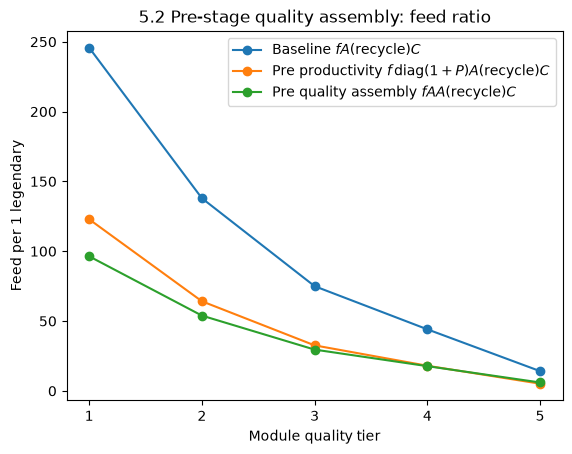

5 星建筑主循环: 全品质插件（产能禁用, P=50% 仅机器内部）
基线 fA(循环)C                 : 传奇产出 = 3.32226% | 进料比 = 30.1 : 1 | 与闭式之差 = 1.7e-13
前置纯产能 f diag(1+P)A(循环)C  : 传奇产出 = 9.13623% | 进料比 = 10.9454 : 1 | 与闭式之差 = 4.6e-13
前置建筑 f diag(1+50%)A(循环)C  : 传奇产出 = 4.9834% | 进料比 = 20.0666 : 1 | 与闭式之差 = 2.5e-13
前置品质组装 fAA(循环)C         : 传奇产出 = 8.49678% | 进料比 = 11.7692 : 1 | 与闭式之差 = 1.9e-13


In [7]:
import matplotlib.pyplot as plt

# 原材料品质组装 vs 纯产能前置：主循环取 4.3 的最优配比，在其上增加前置组装
tiers = list(range(1, 6))
y_base, y_prod, y_qual = [], [], []
for q_t in tiers:
    R = recycler(q_t=q_t)
    # 4.3 最优配比：枚举 p_n 取传奇产出最大者
    best_y, best_p_n = max(
        (
            legendary_yield(
                electromagnetic_plant(q_n=5 - p_n, q_t=q_t, p_n=p_n, p_t=q_t), R
            )[0],
            p_n,
        )
        for p_n in range(6)
    )
    p_n, q_n = best_p_n, 5 - best_p_n
    A = electromagnetic_plant(q_n=q_n, q_t=q_t, p_n=p_n, p_t=q_t)  # 主循环：4.3 最优配比
    A_q = electromagnetic_plant(q_n=5, q_t=q_t, p_n=0, p_t=0)  # 前置品质组装：5个品质插件，内部产能 50%
    # 纯产能前置 = 同一台前置机改为 5 个产能插件：内部产能 50% + 5 x 单件产能
    P_q = MACHINES["电磁工厂"]["base_productivity"] + 5 * PRODUCTIVITY_MOD3[q_t]

    P_main = MACHINES["电磁工厂"]["base_productivity"] + p_n * PRODUCTIVITY_MOD3[q_t]
    print(f"{q_t} 星 CPU 主循环最优: 产能x{p_n} 品质x{q_n}（q={q_n * QUALITY_MOD3[q_t]:.1%}, P={P_main:.0%}）")
    for label, head, bucket in (
        ("基线 fA(循环)C                 ", np.eye(5), y_base),
        ("前置纯产能 f diag(1+P)A(循环)C  ", diag([1 + P_q] * 5), y_prod),
        ("前置品质组装 fAA(循环)C         ", A_q, y_qual),
    ):
        y_leg, diff = legendary_yield(A, R, head=head)
        bucket.append(1 / y_leg)
        print(
            f"{label}: 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1"
            f" | 与闭式之差 = {diff:.1e}"
        )
    print()

# 折线图：进料比（进料/传奇产出）vs 插件品质星级
plt.figure()
plt.plot(tiers, y_base, marker="o", label=r"Baseline $fA(\mathrm{recycle})C$")
plt.plot(tiers, y_prod, marker="o", label=r"Pre productivity $f\,\mathrm{diag}(1+P)A(\mathrm{recycle})C$")
plt.plot(tiers, y_qual, marker="o", label=r"Pre quality assembly $fAA(\mathrm{recycle})C$")
plt.xticks(tiers)
plt.xlabel("Module quality tier")
plt.ylabel("Feed per 1 legendary")
plt.title("5.2 Pre-stage quality assembly: feed ratio")
plt.legend()
plt.show()

# 5星直接做建筑：产能插件禁用（节能插件无加成），矩阵无额外 P，只剩机器内部产能 50%
q_t = 5
A_b = electromagnetic_plant(q_n=5, q_t=q_t, p_n=0, p_t=0)  # 全品质（节能无数学效果）
R = recycler(q_t=q_t)
A_q = electromagnetic_plant(q_n=5, q_t=q_t, p_n=0, p_t=0)  # 前置做中间品不受建筑限制
# 前置也是建筑：产能插件禁用，只剩机器内部产能 50%
P_q = MACHINES["电磁工厂"]["base_productivity"] + 5 * PRODUCTIVITY_MOD3[q_t]

print(f"5 星建筑主循环: 全品质插件（产能禁用, P={MACHINES['电磁工厂']['base_productivity']:.0%} 仅机器内部）")
for label, head in (
    ("基线 fA(循环)C                 ", np.eye(5)),
    ("前置纯产能 f diag(1+P)A(循环)C  ", diag([1 + P_q] * 5)),
    ("前置建筑 f diag(1+50%)A(循环)C  ", diag([1 + MACHINES["电磁工厂"]["base_productivity"]] * 5)),
    ("前置品质组装 fAA(循环)C         ", A_q),
):
    y_leg, diff = legendary_yield(A_b, R, head=head)
    print(
        f"{label}: 传奇产出 = {y_leg * 100:.6g}% | 进料比 = {1 / y_leg:.6g} : 1"
        f" | 与闭式之差 = {diff:.1e}"
    )

### 5.3 不养品质虫：产能插件固定 1 星

不打算养品质虫时，产能插件只能选 3 级 1 星（+10%/件），品质插件可以在 1~5 星间变化。下面对电磁工厂枚举最佳配比（产能插件固定 1 星），输出各品质级的产品分布，并画出传奇进料比随品质插件星级变化的折线图。

1 星品质（产能固定 1 星）: 最优 产能x0 品质x5 | 传奇产出 = 0.406905% | 进料比 = 245.758 : 1 | 各级产出% = [186.253  41.787   9.185   2.124   0.407]
2 星品质（产能固定 1 星）: 最优 产能x0 品质x5 | 传奇产出 = 0.723038% | 进料比 = 138.305 : 1 | 各级产出% = [173.716  49.749  12.183   3.195   0.723]
3 星品质（产能固定 1 星）: 最优 产能x0 品质x5 | 传奇产出 = 1.21863% | 进料比 = 82.0597 : 1 | 各级产出% = [160.428  57.522  15.519   4.581   1.219]
4 星品质（产能固定 1 星）: 最优 产能x0 品质x5 | 传奇产出 = 1.77205% | 进料比 = 56.4319 : 1 | 各级产出% = [149.598  63.386  18.289   5.892   1.772]
5 星品质（产能固定 1 星）: 最优 产能x0 品质x5 | 传奇产出 = 3.32226% | 进料比 = 30.1 : 1 | 各级产出% = [128.504  73.728  23.588   8.865   3.322]


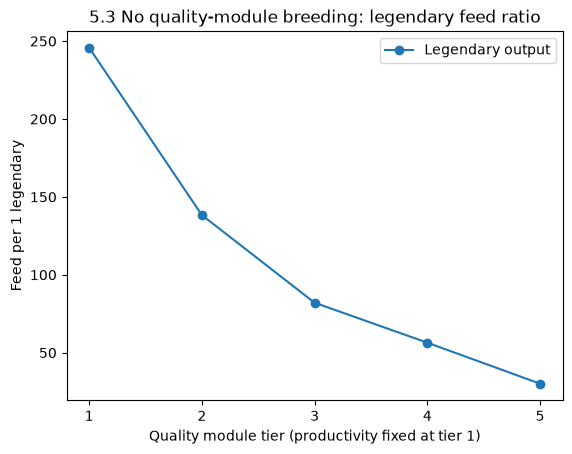

In [8]:
import matplotlib.pyplot as plt

# 不养品质虫：产能插件固定 3级1星（+10%），品质插件 1~5 星，电磁工厂枚举最佳配比
p_t = 1  # 产能插件固定 1 星
tiers = list(range(1, 6))
y_legs = []
p_levels = []  # 各品质级产出（占进料 %）
for q_t in tiers:
    R = recycler(q_t=q_t)
    best_y, best_p_n = max(
        (
            legendary_yield(
                electromagnetic_plant(q_n=5 - p_n, q_t=q_t, p_n=p_n, p_t=p_t), R
            )[0],
            p_n,
        )
        for p_n in range(6)
    )
    p_n, q_n = best_p_n, 5 - best_p_n
    A = electromagnetic_plant(q_n=q_n, q_t=q_t, p_n=p_n, p_t=p_t)
    p_vec = f @ A @ np.linalg.inv(np.eye(5) - S @ R @ A)  # 各品质级总产出/进料
    y_legs.append(1 / best_y)
    p_levels.append(1 / p_vec)
    print(
        f"{q_t} 星品质（产能固定 1 星）: 最优 产能x{p_n} 品质x{q_n}"
        f" | 传奇产出 = {best_y * 100:.6g}% | 进料比 = {1 / best_y:.6g} : 1"
        f" | 各级产出% = {np.array2string(p_vec * 100, precision=3)}"
    )

# 折线图：传奇进料比（进料/传奇产出）vs 品质插件星级
plt.figure()
plt.plot(tiers, y_legs, marker="o", label="Legendary output")
plt.xticks(tiers)
plt.xlabel("Quality module tier (productivity fixed at tier 1)")
plt.ylabel("Feed per 1 legendary")
plt.title("5.3 No quality-module breeding: legendary feed ratio")
plt.legend()
plt.show()